In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math
import copy
from skimage.metrics import structural_similarity as ssim, mean_squared_error as mse

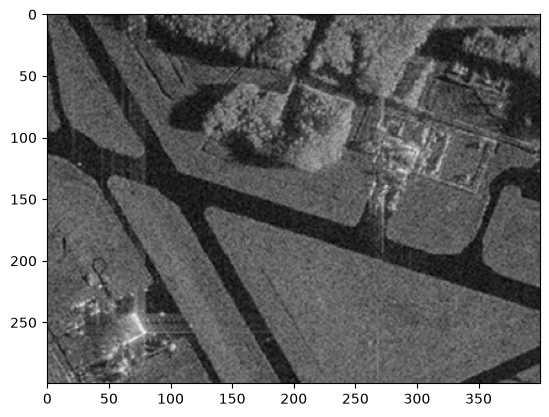

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")

# Алгоритм разрастания регионов

In [3]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False

def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask

    return mask*255

3
5
7
9
11
13
15
17
19
21
23
25
27
28
28
29
30
32
34
34
34
35
37
39
40
41
43
44
44
46
47
48
49
50
50
52
52
53
53
54
56
58
58
60
61
62
64
64
66
66
68
70
70
71
73
73
74
76
77
78
78
80
82
83
84
85
86
86
87
89
89
90
92
93
95
95
97
98
99
101
101
102
103
105
106
107
108
110
111
111
112
114
115
116
117
119
119
120
122
123
123
124
125
127
128
128
129
130
131
133
134
134
136
138
139
139
140
140
142
144
145
145
147
148
148
150
151
153
154
155
155
157
157
158
160
161
163
164
165
166
101
100
99
100
101
99
98
97
96
96
96
95
95
95
95
94
94
94
94
93
93
93
93
93
92
90
90
90
91
89
89
89
89
89
89
89
87
87
87
87
86
86
86
86
85
85
85
85
84
84
83
83
83
82
82
82
81
81
81
81
81
80
79
79
79
78
78
77
75
74
74
73
72
72
71
70
70
69
68
67
66
66
65
63
63
63
64
64
61
60
60
58
58
57
56
56
55
54
53
51
51
49
49
49
48
48
46
46
46
45
43
43
41
41
39
39
39
37
37
36
35
34
34
33
32
31
31
0


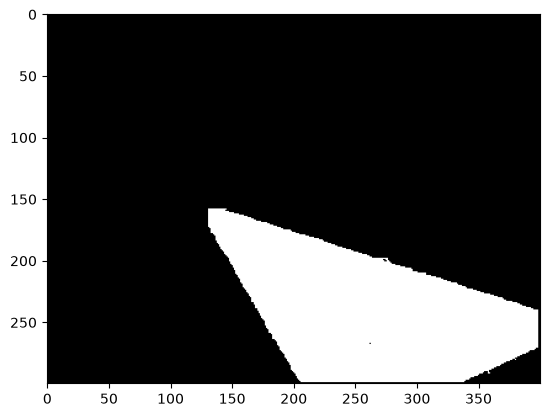

In [6]:
seed_point = (158,131)
mask = region_growing(image_gray, seed_point, homo_average, 1, 40)
plt.imshow(mask, cmap="gray")

Задав максимально крайнюю точку области и порог 40, удалось выделить газон

## 2. Применение своего алгоритма критерия однородности

# Алгоритм медианы абсолютных отклонений

3
5
7
9
11
13
15
17
19
21
23
25
27
28
28
29
30
32
34
34
34
35
37
39
40
41
43
44
44
46
47
48
49
50
50
52
52
53
53
54
56
58
58
60
61
62
64
64
66
66
68
69
70
71
73
73
74
76
77
78
78
80
82
82
84
84
86
86
87
88
89
90
92
93
95
95
97
98
99
100
100
102
103
104
106
107
108
110
111
111
112
114
115
116
117
118
119
120
122
123
123
124
125
127
128
128
129
130
131
133
134
134
136
138
139
139
140
140
142
144
145
145
147
148
148
150
151
153
154
155
155
157
157
158
160
161
163
164
165
166
101
100
99
100
101
99
98
97
96
96
96
95
95
95
95
94
94
94
94
93
93
93
93
93
92
90
90
90
90
89
89
89
89
89
89
89
87
87
87
87
86
86
86
86
85
85
85
85
84
84
83
83
83
82
84
82
81
81
81
81
81
80
79
79
79
78
78
77
75
74
74
73
72
72
71
70
70
69
68
67
66
66
65
63
63
63
64
64
61
60
60
58
58
57
56
56
55
54
53
51
51
49
49
49
48
48
46
46
46
45
43
43
41
41
39
39
39
37
37
36
35
34
34
33
32
31
31
0


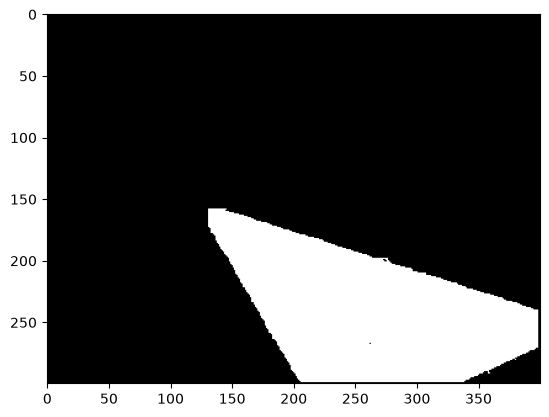

In [8]:
def homo_median_mad(img, mask, point, T):
    region_pixels = img[mask > 0]
    median = np.median(region_pixels)
    mad = np.median(np.abs(region_pixels - median))
    return abs(median - img[point]) <= T and mad <= T / 2

seed_point = (158, 131)
mask_mad = region_growing(image_gray, seed_point, homo_median_mad, 1, 40)
plt.imshow(mask_mad, cmap="gray")

In [9]:
mask_n = mask.astype(np.float32) / 255
mask_mad_n = mask_mad.astype(np.float32) / 255

mse_val = mse(mask_n, mask_mad_n)
ssim_val = ssim(mask_n, mask_mad_n, data_range=1.0)

print(f"MSE между масками:  {mse_val:.4f}")
print(f"SSIM между масками: {ssim_val:.4f}")

MSE между масками:  0.0001
SSIM между масками: 0.9996


## 3. Применение алгоритма сегментации watershed+distance transform для подсчета пальмовых деревьев

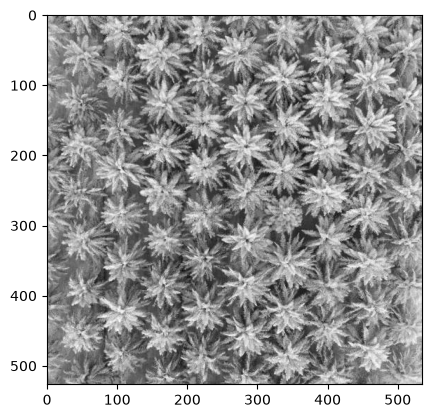

In [10]:
image_palm = cv2.imread('palm_1.jpg')
image_gray_palm = cv2.cvtColor(image_palm, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray_palm, cmap="gray")

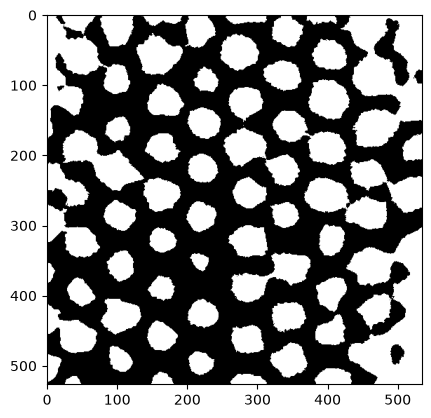

In [11]:
image_blurred = cv2.GaussianBlur(image_gray_palm, (15, 15), 0)
image_median = cv2.medianBlur(image_gray_palm, 7)

image_bilateral = cv2.bilateralFilter(image_gray_palm, 25, 150, 200) 
ret, thresh_palm = cv2.threshold(image_bilateral, 0, 255, cv2.THRESH_OTSU)

plt.imshow(thresh_palm, cmap="gray")

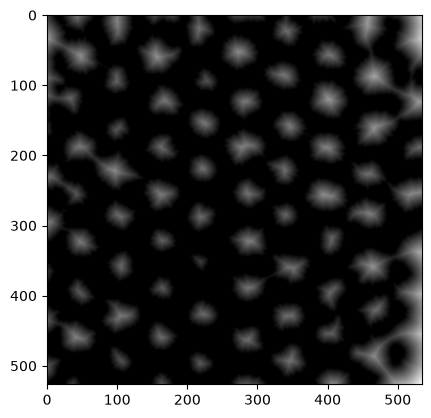

In [12]:
dist_palm = cv2.distanceTransform(thresh_palm, cv2.DIST_L2, 5)
plt.imshow(dist_palm, cmap="gray")

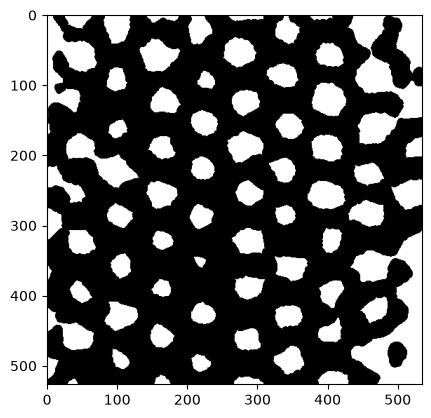

In [13]:
ret, sure_fg_palm = cv2.threshold(
    dist_palm, 0.1 * dist_palm.max(), 255, cv2.THRESH_BINARY
)

plt.imshow(sure_fg_palm, cmap="gray")

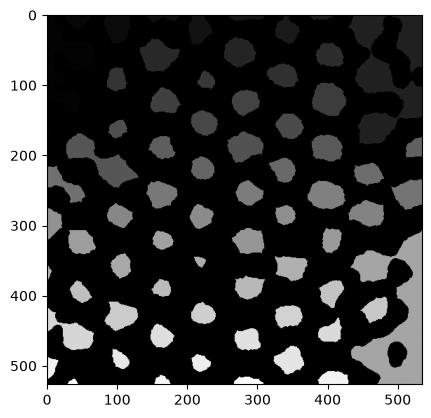

In [14]:
sure_fg_palm = sure_fg_palm.astype(np.uint8)
ret, markers_palm = cv2.connectedComponents(sure_fg_palm)
plt.imshow(markers_palm, cmap="gray")

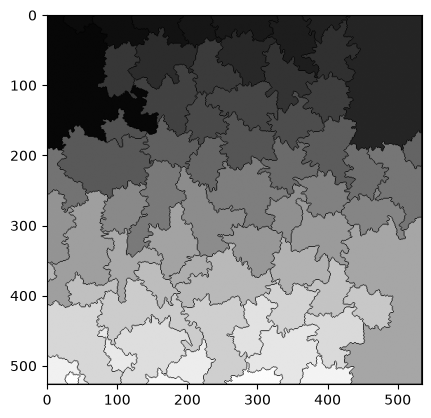

In [17]:
markers_palm = cv2.watershed(image_palm, markers_palm)
plt.imshow(markers_palm, cmap="gray")

In [18]:
unique_markers_palm = np.unique(markers_palm)
tree_markers_palm = unique_markers_palm[unique_markers_palm > 0]
num_palms = len(tree_markers_palm)

print(num_palms)

68


Применив билатеральный фильтр, получилось явно отделить пальмы друг от друга.